# Titanic · 03. Ошибки и интерпретация

В [02_models](02_models.ipynb) выбрали CatBoost (основная) и логистическую регрессию (резервная).
Здесь разбираем **на ком и почему** они ошибаются:
1. Карта ошибок: в каких группах сосредоточены промахи.
2. Самые уверенные ошибки — читаем истории конкретных людей.
3. Где CatBoost и LogReg расходятся и кто из них прав.
4. Как модель принимает решения: веса логрега и SHAP для CatBoost.
5. Порог 0.5 — оптимален ли?
6. Сколько ещё можно выжать: оценка неустранимой ошибки.

In [1]:
import warnings

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from catboost import CatBoostClassifier

from kagglib.titanic import features as F
from kagglib.titanic import model as M
from kagglib.titanic.cv import make_folds, oof_proba

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110

DATA = "../../data/kaggle/titanic"
train = pl.read_csv(f"{DATA}/train.csv")
test = pl.read_csv(f"{DATA}/test.csv")
y = train["Survived"].to_numpy()

CAT = CatBoostClassifier(**M.CATBOOST_PARAMS)
LR = make_pipeline(StandardScaler(), LogisticRegression(C=M.LOGREG_C, max_iter=2000))

folds = make_folds(train, test, n_splits=5, n_repeats=5)
oof = pd.DataFrame({"cat": oof_proba(CAT, folds, len(y)), "lr": oof_proba(LR, folds, len(y))})
print(f"OOF accuracy: CatBoost {((oof.cat >= .5) == y).mean():.4f}, LogReg {((oof.lr >= .5) == y).mean():.4f}")

# Таблица для разбора: сырые колонки + OOF + удобные группы
df = train.with_columns(
    pl.Series("p_cat", oof["cat"].to_numpy()), pl.Series("p_lr", oof["lr"].to_numpy()),
    pl.col("Name").str.extract(r",\s*([^\.]+)\.").alias("Title"),
    (pl.col("Sex") + " " + pl.col("Pclass").cast(pl.String)).alias("SexClass"),
).with_columns(
    ((pl.col("p_cat") >= 0.5).cast(pl.Int64) != pl.col("Survived")).alias("err_cat"),
    ((pl.col("p_lr") >= 0.5).cast(pl.Int64) != pl.col("Survived")).alias("err_lr"),
)

/home/victus/OwnProjects/kaggle/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OOF accuracy: CatBoost 0.8451, LogReg 0.8283


## 1. Карта ошибок

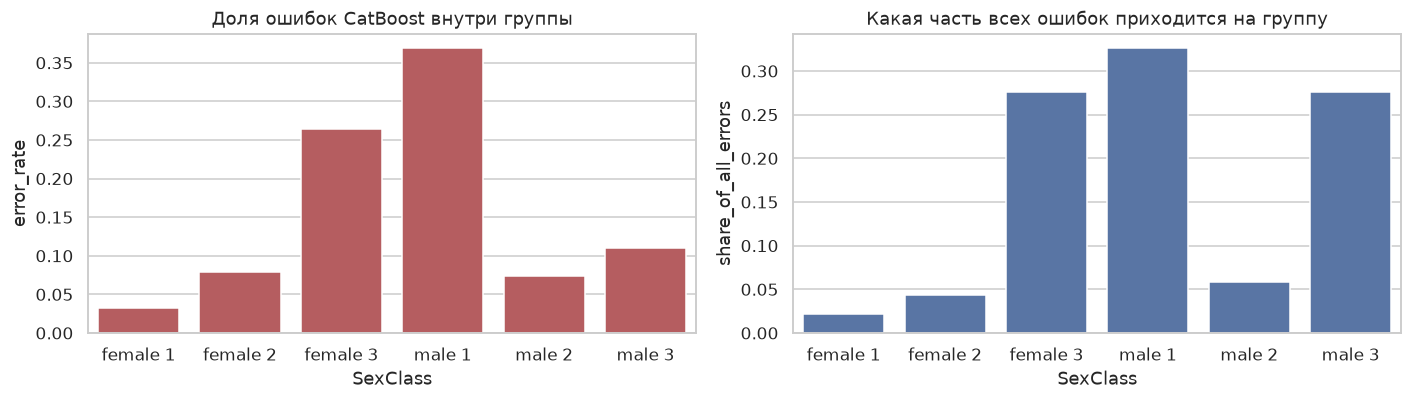

,SexClass,n,errors,surv_rate,error_rate,share_of_all_errors
0,female 1,94,3,0.968,0.032,0.022
1,female 2,76,6,0.921,0.079,0.043
2,female 3,144,38,0.500,0.264,0.275
3,male 1,122,45,0.369,0.369,0.326
4,male 2,108,8,0.157,0.074,0.058
5,male 3,347,38,0.135,0.110,0.275


In [2]:
emap = (df.group_by("SexClass").agg(pl.len().alias("n"), pl.col("err_cat").sum().alias("errors"),
                                    pl.col("Survived").mean().alias("surv_rate"))
          .with_columns((pl.col("errors") / pl.col("n")).alias("error_rate"),
                        (pl.col("errors") / pl.col("errors").sum()).alias("share_of_all_errors"))
          .sort("SexClass").to_pandas())
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.barplot(emap, x="SexClass", y="error_rate", ax=axes[0], color="#c44e52")
axes[0].set_title("Доля ошибок CatBoost внутри группы")
sns.barplot(emap, x="SexClass", y="share_of_all_errors", ax=axes[1], color="#4c72b0")
axes[1].set_title("Какая часть всех ошибок приходится на группу")
plt.tight_layout()
plt.show()
emap.round(3)

Подтверждается гипотеза из EDA: ошибки сосредоточены там, где выживание ближе к 50/50 — **мужчины 1-го класса**
(ошибка 37%, треть всех ошибок) и **женщины 3-го класса** (26%, ещё 27% ошибок). Ещё 27% ошибок — на мужчинах
3-го класса: там ошибка всего 11%, но их самих 347.
В группах «женщины 1-2 класса» модель почти не ошибается — ей там нечего делать, как и правилу «пол».

**Тип ошибок.** Посмотрим отдельно на ложные «выжил» и ложные «погиб».

In [3]:
ct = pd.crosstab(df["Survived"].to_pandas(), (df["p_cat"] >= 0.5).to_pandas().astype(int),
                 rownames=["факт"], colnames=["прогноз"])
print(ct)
fp = df.filter(pl.col("err_cat") & (pl.col("Survived") == 0))
fn = df.filter(pl.col("err_cat") & (pl.col("Survived") == 1))
pd.DataFrame({
    "ложно 'выжил' (FP)": fp.group_by("SexClass").agg(pl.len()).sort("SexClass").to_pandas().set_index("SexClass")["len"],
    "ложно 'погиб' (FN)": fn.group_by("SexClass").agg(pl.len()).sort("SexClass").to_pandas().set_index("SexClass")["len"],
}).fillna(0).astype(int)

прогноз    0    1
факт             
0        494   55
1         83  259


,ложно 'выжил' (FP),ложно 'погиб' (FN)
SexClass,,
female 1,3,0
female 2,6,0
female 3,26,12
male 1,17,28
male 2,0,8
male 3,3,35


Структура ошибок асимметрична: ложные «погиб» — почти всегда **мужчины** (71 из 83: модель не верит, что мужчина спасся),
ложные «выжил» — в основном **женщины** (35 из 55, модель верит полу) плюс мужчины 1-го класса (17), которым модель
поверила из-за дорогого билета. Модель по сути выучила «пол + поправки» и ошибается там,
где поправок не хватает.

## 2. Самые уверенные ошибки

Ошибка при $p = 0.55$ — нормальное дело. Ошибка при $p = 0.95$ — повод посмотреть на человека.

In [4]:
conf = (df.with_columns((pl.col("p_cat") - pl.col("Survived")).abs().alias("miss"))
          .sort("miss", descending=True)
          .select("Name", "Sex", "Age", "Pclass", "SibSp", "Parch", "Ticket", "Fare", "Survived",
                  pl.col("p_cat").round(3), pl.col("p_lr").round(3)).head(15))
conf.to_pandas()

,Name,Sex,Age,Pclass,SibSp,Parch,Ticket,Fare,Survived,p_cat,p_lr
0,"Tornquist, Mr. William Henry",male,25.0,3,0,0,LINE,0.0000,1,0.022,0.013
1,"Isham, Miss. Ann Elizabeth",female,50.0,1,0,0,PC 17595,28.7125,0,0.974,0.936
2,"Allison, Miss. Helen Loraine",female,2.0,1,1,2,113781,151.5500,0,0.973,0.982
3,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0,1,1,2,113781,151.5500,0,0.962,0.978
4,"Harris, Mr. George",male,62.0,2,0,0,S.W./PP 752,10.5000,1,0.039,0.065
5,"Barkworth, Mr. Algernon Henry Wilson",male,80.0,1,0,0,27042,30.0000,1,0.042,0.139
6,"Sundman, Mr. Johan Julian",male,44.0,3,0,0,STON/O 2. 3101269,7.9250,1,0.047,0.055
7,"Dahl, Mr. Karl Edwart",male,45.0,3,0,0,7598,8.0500,1,0.053,0.054
8,"Johannesen-Bratthammer, Mr. Bernt",male,NaN,3,0,0,65306,8.1125,1,0.061,0.070
9,"Albimona, Mr. Nassef Cassem",male,26.0,3,0,0,2699,18.7875,1,0.061,0.069


Пример того, что модель **не может** знать:
- Женщины 1-2 класса, которые погибли, — многие остались с мужьями (известные истории: Ида Штраус отказалась
  садиться в шлюпку без мужа). Этого нет ни в одной колонке.
- Семья Allison (1-й класс): погибли мать и дочь, хотя по всем признакам должны были выжить — они искали
  младенца, которого уже унесла в шлюпку няня. В данных это видно только как «странная» группа по билету.
- Мужчины 3-го класса, которые выжили, — часто случай: спрыгнули в последнюю шлюпку, выплыли.
- Первый в списке, `Tornquist, Mr. William Henry` — билет `LINE` с тарифом 0: это сотрудники пароходной компании,
  ехавшие бесплатно. Тариф 0 модель читает как «самый бедный пассажир», хотя это **артефакт данных**, а не бедность.
  Хороший пример, зачем смотреть на ошибки глазами: такие вещи можно превратить в признак или исправить.

Это **неустранимая ошибка** (Bayes error) для данного набора признаков: никакая модель не отличит двух людей с
одинаковыми признаками и разной судьбой.

## 3. CatBoost против LogReg: где расходятся

расходятся на 57 из 891 (6.4%)
из них прав CatBoost: 36,  прав LogReg: 21


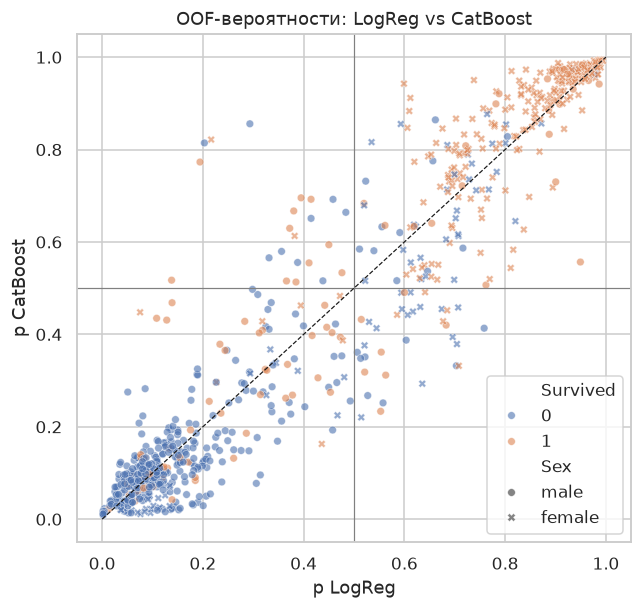

,SexClass,len,прав CatBoost,прав LogReg
0,male 1,30,16,14
1,female 3,21,16,5
2,male 3,5,3,2
3,female 2,1,1,0


In [5]:
dis = df.filter((pl.col("p_cat") >= 0.5) != (pl.col("p_lr") >= 0.5))
print(f"расходятся на {dis.height} из {df.height} ({dis.height / df.height:.1%})")
print(f"из них прав CatBoost: {(~dis['err_cat']).sum()},  прав LogReg: {(~dis['err_lr']).sum()}")
fig, ax = plt.subplots(figsize=(6.5, 6))
sns.scatterplot(df.to_pandas(), x="p_lr", y="p_cat", hue="Survived", style="Sex", alpha=0.6, s=25, ax=ax)
ax.axhline(0.5, c="gray", lw=0.8)
ax.axvline(0.5, c="gray", lw=0.8)
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set(title="OOF-вероятности: LogReg vs CatBoost", xlabel="p LogReg", ylabel="p CatBoost")
plt.show()
dis.group_by("SexClass").agg(pl.len(), (~pl.col("err_cat")).sum().alias("прав CatBoost"),
                             (~pl.col("err_lr")).sum().alias("прав LogReg")).sort("len", descending=True).to_pandas()

Модели расходятся на 57 людях (6.4%), почти все — в двух «сложных» группах. Из 57 споров CatBoost прав в 36.
Разница — почти целиком **женщины 3-го класса**: там CatBoost прав в 16 случаях из 21. Это ровно тот **нелинейный**
эффект (пол × класс × размер семьи × группа), который линейная модель усредняет. На мужчинах 1-го класса
счёт почти равный (16:14) — там обе модели гадают. Именно поэтому LogReg полезен в проде как контрольная модель: массовое
расхождение между ними на новых данных — сигнал сдвига данных.

## 4. Как модели принимают решения

### Веса логистической регрессии
Признаки стандартизованы, поэтому вес $w_j$ — изменение логарифма шансов при сдвиге признака на одно стандартное
отклонение. $e^{w_j}$ — во сколько раз меняются шансы.

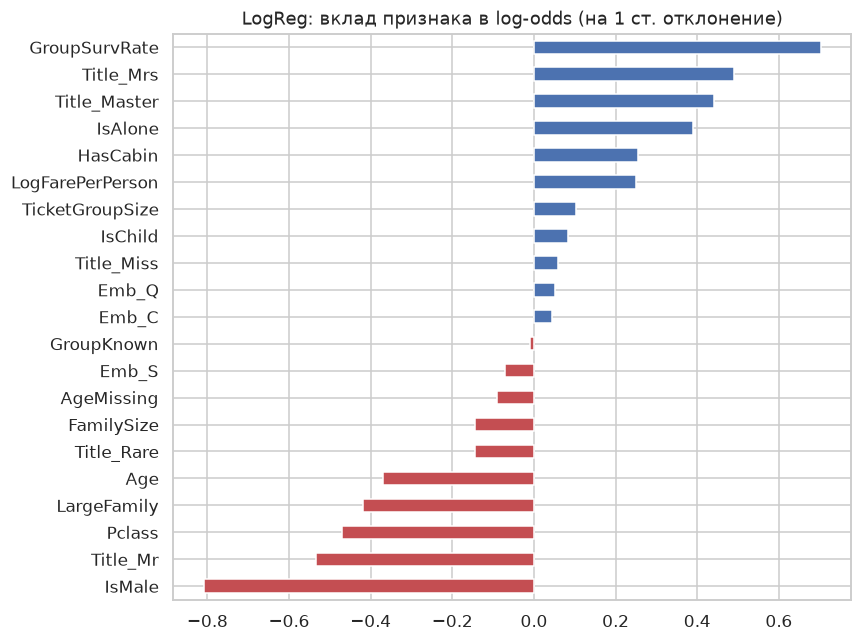

In [6]:
ctx = F.full_context(train, test)
state = F.fit(train, ctx)
X_full = F.transform(train, state, ctx).select(F.FEATURES).to_pandas()
lr_full = LR.fit(X_full, y)
coef = pd.Series(lr_full[-1].coef_[0], index=F.FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
coef.plot.barh(ax=ax, color=np.where(coef > 0, "#4c72b0", "#c44e52"))
ax.set_title("LogReg: вклад признака в log-odds (на 1 ст. отклонение)")
plt.tight_layout()
plt.show()

Осторожно с интерпретацией: `IsMale` и `Title_Mr` почти дублируют друг друга (мультиколлинеарность), и логрег
делит между ними вес как придётся. Ещё пример: `IsAlone` получил **положительный** вес, хотя одиночки выживали
реже (30%). Это не противоречие: вес — эффект *при прочих равных*. Среди мужчин 3-го класса одиночке легче, чем
отцу большой семьи, а то, что одиночки в среднем — бедные мужчины, уже объяснили `IsMale` и `Pclass`. Смотреть надо на **сумму** коррелированных признаков, а не на каждый в отдельности.
Регуляризация (C = 0.3) как раз не даёт этим весам разъехаться в разные стороны.

### SHAP для CatBoost
**Матчасть.** SHAP раскладывает предсказание на вклады признаков по **значениям Шепли** из теории кооперативных игр:
вклад признака — его средний маргинальный вклад по всем порядкам добавления признаков. Это единственный способ
раскладки, у которого есть аддитивность (вклады + база = предсказание), симметрия и «нулевой игрок».
Для деревьев (TreeSHAP) он считается точно и быстро. Вклады в log-odds.

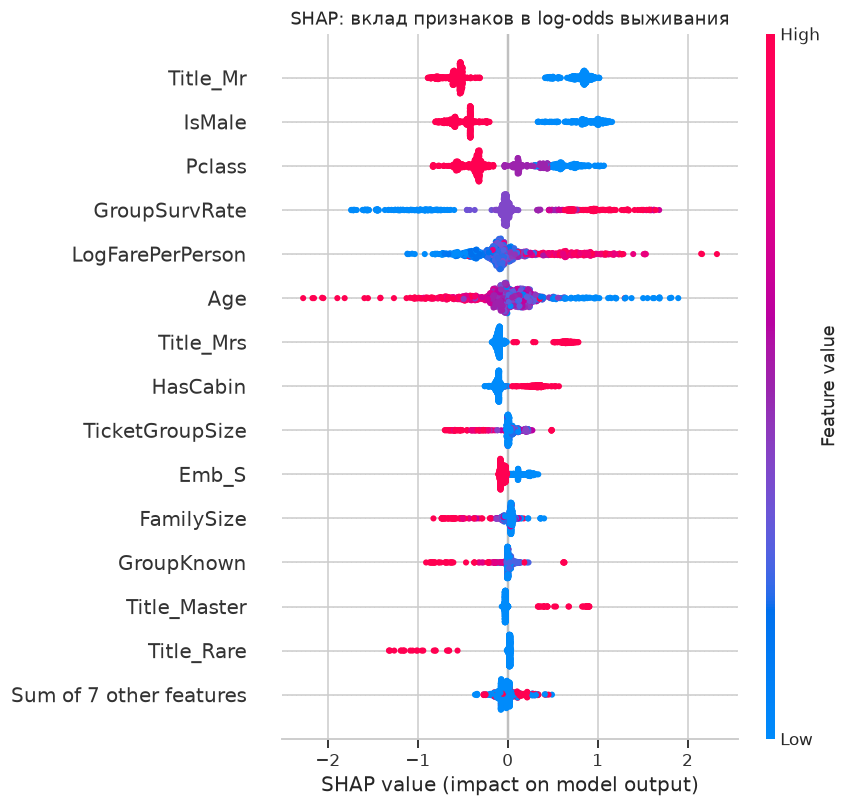

In [7]:
cat_full = CatBoostClassifier(**M.CATBOOST_PARAMS).fit(X_full, y)
explainer = shap.TreeExplainer(cat_full)
sv = explainer(X_full)
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("SHAP: вклад признаков в log-odds выживания")
plt.tight_layout()
plt.show()

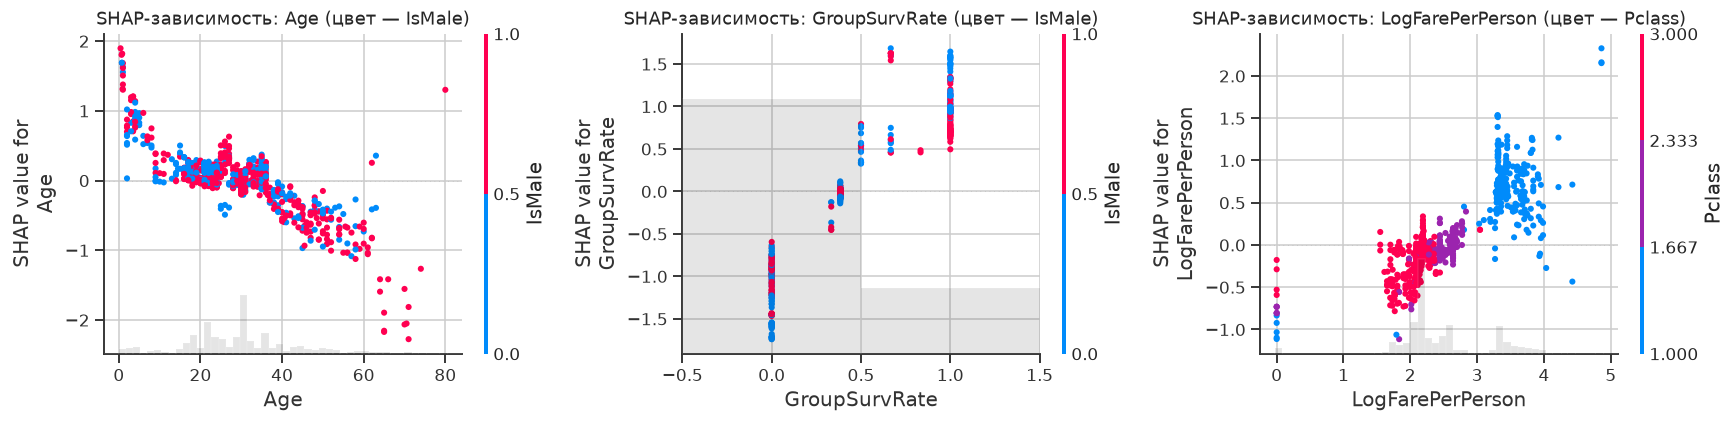

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, f, c in zip(axes, ["Age", "GroupSurvRate", "LogFarePerPerson"], ["IsMale", "IsMale", "Pclass"]):
    shap.plots.scatter(sv[:, f], color=sv[:, c], ax=ax, show=False)
    ax.set_title(f"SHAP-зависимость: {f} (цвет — {c})")
plt.tight_layout()
plt.show()

**Что видим:**
- **Пол/титул** — самые большие вклады, как и ожидалось.
- **Age**: резкий положительный вклад у детей (до +1.8 к log-odds у младенцев) и плавное снижение со старостью.
  Модель сама нашла «женщины и дети» без подсказки. Одинокая точка справа (80 лет, +1.3) — это Barkworth, выживший
  80-летний мужчина из 1-го класса: SHAP посчитан на обучающих данных, и видно, как бустинг **запомнил конкретного
  человека**. На валидации такой «правды» нет — это и есть переобучение, видимое глазами.
- **GroupSurvRate**: монотонно — чем больше попутчиков выжило, тем выше шанс; значение-приор (0.38, «попутчики неизвестны»)
  даёт около нуля — модель правильно поняла, что это «нет информации».
- **Тариф**: внутри класса дороже → выше шанс (каюты ближе к шлюпочной палубе).

### Локальное объяснение: одна женщина 3-го класса

{'Name': 'Skoog, Mrs. William (Anna Bernhardina Karlsson)', 'Age': 45.0, 'SibSp': 1, 'Parch': 4, 'Ticket': '347088', 'Survived': 0}


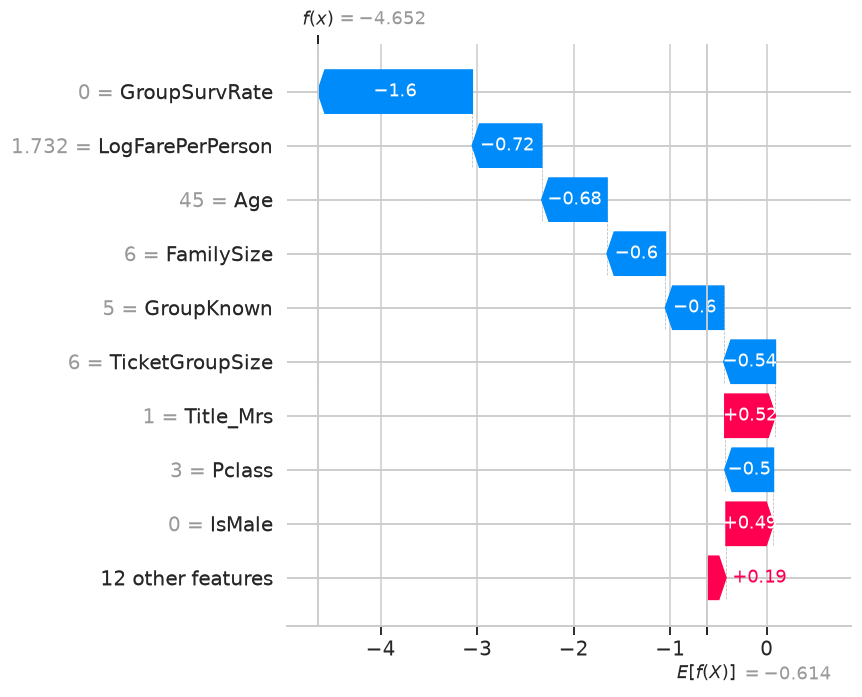

In [9]:
idx = df.with_row_index().filter((pl.col("SexClass") == "female 3") & (pl.col("SibSp") + pl.col("Parch") >= 3)) \
        .sort("p_cat")["index"][0]
print(train[int(idx)].select("Name", "Age", "SibSp", "Parch", "Ticket", "Survived").to_dicts()[0])
shap.plots.waterfall(sv[int(idx)], max_display=10, show=False)
plt.tight_layout()
plt.show()

Так выглядит объяснение одного предсказания: от базовой ставки (средний log-odds −0.61) каждый признак толкает
вверх или вниз. Миссис Скуг, 45 лет, 3-й класс, с мужем и четырьмя детьми: женский пол и титул Mrs дают +1.0,
но погибшие попутчики (−1.6), дешёвый билет, возраст, большая семья и 3-й класс вместе дают около −5.
Итог −4.65 в log-odds, то есть вероятность ~1%. Так и было: погибла вся семья. В проде такие объяснения
можно отдавать вместе с вероятностью.

## 5. Оптимален ли порог 0.5?

Для accuracy оптимальный порог — 0.5, **если вероятности откалиброваны**. Проверим на OOF.

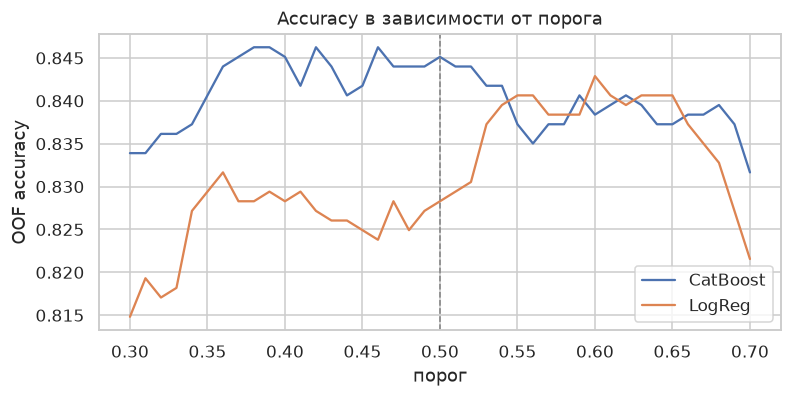

лучший порог CatBoost: 0.38  (0.8462 против 0.8451 при 0.5)


In [10]:
th = np.linspace(0.3, 0.7, 41)
acc_c = [((oof.cat >= t) == y).mean() for t in th]
acc_l = [((oof.lr >= t) == y).mean() for t in th]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(th, acc_c, label="CatBoost")
ax.plot(th, acc_l, label="LogReg")
ax.axvline(0.5, c="gray", ls="--", lw=1)
ax.set(xlabel="порог", ylabel="OOF accuracy", title="Accuracy в зависимости от порога")
ax.legend()
plt.show()
print(f"лучший порог CatBoost: {th[int(np.argmax(acc_c))]:.2f}  ({max(acc_c):.4f} против {((oof.cat >= .5) == y).mean():.4f} при 0.5)")

Кривая плоская вокруг 0.5 — подбирать порог под accuracy бессмысленно (выигрыш — доли процента, то есть шум).
Порог имеет смысл менять, когда цена ошибок **разная** (в медицине, антифроде), — тогда его выбирают по стоимости,
а не по accuracy.

## 6. Сколько ещё можно выжать?

Грубая оценка неустранимой ошибки: найдём пассажиров с **одинаковым** набором ключевых признаков и посмотрим,
насколько их судьбы расходятся. Если в группе одинаковых по признакам людей выжила половина — никакая модель
не угадает больше половины из них.

In [11]:
key = ["Sex", "Pclass", "Title", "SibSp", "Parch", "Embarked"]
grp = df.group_by(key).agg(pl.len().alias("n"), pl.col("Survived").mean().alias("rate"))
best_possible = (df.join(grp, on=key)
                   .with_columns(pl.max_horizontal(pl.col("rate"), 1 - pl.col("rate")).alias("best"))["best"].mean())
print(f"accuracy «оракула», который знает долю выживших в каждой группе одинаковых людей: {best_possible:.3f}")
print("(это оптимистичная оценка: оракул подсматривает в таргет; честный потолок ниже)")

accuracy «оракула», который знает долю выживших в каждой группе одинаковых людей: 0.856
(это оптимистичная оценка: оракул подсматривает в таргет; честный потолок ниже)


Даже оракул, который знает точную долю выживших в каждой комбинации признаков, — около этой планки. Наши модели
на честной CV — около 0.84. **Зазор маленький**: на этих признаках мы близко к потолку. Дальше — либо новые
признаки (что-то, чего нет в анкете: кто кого ждал у шлюпки), либо подгонка под шум лидерборда.

## Мысли

1. **Модель ошибается там же, где и человек.** Женщины 3-го класса и мужчины 1-го — те же 50/50, что мы видели в EDA.
   Анализ ошибок не открыл новой «дыры», а подтвердил: всё, что можно, модель уже взяла из признаков.
2. **Уверенные ошибки — это истории.** За каждым промахом с p > 0.9 — поступок, которого нет в данных (осталась с мужем,
   искала ребёнка). Хороший анализ ошибок всегда заканчивается вопросом «какие данные мы не собираем».
3. **Две модели в проде лучше одной.** Расхождение CatBoost и LogReg на новой партии — дешёвый детектор сдвига данных,
   не требующий меток.
4. **Интерпретация зависит от корреляций.** Веса логрега между `IsMale` и `Title_Mr` делятся произвольно; SHAP честнее,
   но тоже распределяет вклад между коррелированными признаками по своей аксиоматике. Объяснение ≠ причинность.
5. **Порог — бизнес-решение.** Для accuracy 0.5 оптимален, но в задачах с разной ценой ошибок порог выбирают по деньгам.
   Когда будет соревнование с асимметричной метрикой — вернёмся к этому.